In [1]:
     library(dplyr)
        library(ggplot2)
        library(patchwork)
        library(rlang)
        library(UpSetR)
        library(Seurat)
        #library(UCell)
        library(ggExtra)
        library(fgsea)
        library(DOSE)
        library(org.Hs.eg.db)
        library(tidyverse)
        library(SeuratObject)
        library(DropletUtils)
        library(Ckmeans.1d.dp)
        library(igraph)
        library(tidyverse)
        library(patchwork)
        library(viridis)
        library(conflicted)
        library(scCustomize)
        library(qs)
        library(ggpubr)
        library(clustree)
        library(ggraph)
        library(Nebulosa)
        library(ggalluvial)
        library(MAST)
        library(pheatmap)
        library(ape)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.3; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed

‘SeuratObject’ was built with package ‘Matrix’ 1.7.0 but the current
version is 1.7.3; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t




DOSE v3.30.5  For help: https://yulab-smu.top/biomedical-knowledge-mining-book/

If you use DOSE in published research, please cite:
Guangchuang Yu, Li-Gen Wang, Guang-Rong Yan, Qing-Yu He. DOSE: an R/Bioconductor package for Disease Ontology Semantic and Enrichment analysis. 

In [2]:
VDJ_PATH  = read.csv("/media/igl2/828f6e4d-cda7-48c0-99c1-478e80aeecda/Shubham/clonotype_DS2/filtered_contig_annotations.csv")
bcell = readRDS("/media/igl2/828f6e4d-cda7-48c0-99c1-478e80aeecda/Shubham/demuxx/DS2/ds2.qc.norm.rds")
bcell@meta.data %>% dim()

[1] 7642   18

In [3]:
conflicts_prefer(dplyr::filter)

[conflicted] Will prefer dplyr::filter over any other package.


In [4]:
# bcell[["HTO"]]@data %>% t() -> hto
# #write.csv(hto, "/media/igl2/828f6e4d-cda7-48c0-99c1-478e80aeecda/Shubham/clonotype_AS/hto.csv")

In [5]:
 demux.singlet <- bcell@meta.data %>% as.data.frame() %>% rownames_to_column("barcode") %>% 
        filter(DoubletStatus %in% c("Singlet", "Negative"))
# head(demux.singlet)
dim(demux.singlet)

[1] 7642   19

In [6]:
ctype <- VDJ_PATH %>% dplyr::select(barcode, raw_clonotype_id) %>% distinct()
head(ctype)
dim(ctype)

,barcode,raw_clonotype_id
,<chr>,<chr>
1,AAACCTGTCCTTGGTC-1,clonotype145
2,AAACGGGGTAAAGGAG-1,clonotype245
3,AAAGCAAAGTTACGGG-1,clonotype249
4,AAAGCAATCCGTTGCT-1,clonotype137
5,AAAGTAGTCTGGTTCC-1,clonotype135
6,AAATGCCAGATCTGCT-1,clonotype338


[1] 523   2

In [8]:
dmx.ctype <- merge(demux.singlet, ctype, by = "barcode", 
        all.x = TRUE) %>% add_count(raw_clonotype_id, name = "frequency") %>% 
        mutate(expanded = ifelse(frequency > 1, "Yes", "No"))
# head(dmx.ctype)
dim(dmx.ctype)


[1] 7642   22

In [9]:
ct.cls <- dmx.ctype %>% dplyr::select(seurat_clusters, 
            raw_clonotype_id, Donor)
dim(ct.cls)

[1] 7642    3

In [10]:
ct.cls$seurat_clusters <- as.character(ct.cls$seurat_clusters)
head(ct.cls$seurat_clusters)

[1] "0" "0" "5" "5" "1" "0"

In [11]:
vs <- ct.cls$seurat_clusters %>% unique()
        vlst <- list()
        for (v in vs) {
            vlst[[v]] <- ct.cls[ct.cls$seurat_clusters == v, 
                "raw_clonotype_id"]}


In [12]:
#vlst


In [13]:
#png("/media/igl2/828f6e4d-cda7-48c0-99c1-478e80aeecda/Shubham/clonotype_AS/upset_cluster.png", width = 1000, height = 900)
  #      print(upset(fromList(vlst), order.by = "freq", text.scale = c(2, 
    #        2, 2, 2, 2, 2), point.size = 3, line.size = 1.5, 
   #         nsets = 17, number.angles = 0))
       # dev.off()

In [15]:
# bcell@meta.data$Donor %>% unique()
length(bcell@meta.data$Donor %>% unique())

[1] 10

In [16]:
idx <- dmx.ctype$Donor
        jdst <- list()
        for (i in idx) {
            jdst[[i]] <- ct.cls[ct.cls$Donor == i, "raw_clonotype_id"]
        }


In [17]:
png("/media/igl2/828f6e4d-cda7-48c0-99c1-478e80aeecda/Shubham/clonotype_DS2/upset_donor.png", width = 1050, height = 600)
        print(upset(fromList(jdst), order.by = "freq", text.scale = c(2, 
            2, 2, 2, 2, 2), point.size = 3, line.size = 1.5, 
            nsets = 17, number.angles = 0))
        dev.off()

pdf 
  2

In [18]:
ct <- dmx.ctype$raw_clonotype_id %>% gsub("clonotype", 
            "", .) %>% as.numeric() %>% sort() %>% unique()
head(ct)
length(ct)

[1] 1 2 3 5 6 8

[1] 253

In [19]:
clonotypes <- sapply(ct, FUN = function(x) {
            return(sprintf("clonotype%d", x))
        })
head(clonotypes)
nc <- length(clonotypes)

[1] "clonotype1" "clonotype2" "clonotype3" "clonotype5" "clonotype6"
[6] "clonotype8"

In [20]:
 Donors <- dmx.ctype$Donor %>% unique()
        dv <- expand.grid(Donors)
        colnames(dv) <- c("Donor")
        dv$Donor <- as.character(dv$Donor)
# head(dv$Donor)

In [21]:
ctdata <- list()

In [22]:
tmp <- 1
        for (ct in clonotypes) {
            p <- round((tmp/nc) * 100, 2)
            tmp <- tmp + 1
            cat(sprintf("%0.2f%% complete\r", p))
            flush.console()
            ctdata[[ct]] <- c()
            for (i in 1:nrow(dv)) {
                dnr <- dv[i, "Donor"]
                ctdata[[ct]] <- c(ctdata[[ct]], filter(dmx.ctype, 
                  ((Donor == dnr) & (raw_clonotype_id == 
                    ct))) %>% nrow())
            }
        }

In [23]:
ftab <- as.data.frame(t(ctdata %>% data.frame()))
        colnames(ftab) <- paste(dv$Donor)


In [24]:
maccounts <- as.data.frame((as.numeric(rowSums(ftab))))
colnames(maccounts) <- "Total"


In [25]:
D <- cbind(maccounts, ftab)


In [26]:
A <- as.data.frame(t(dv))


In [27]:
 B <- cbind(c("NA", "NA"), A)
colnames(B) <- c("Total", colnames(ftab))

Warning message in data.frame(..., check.names = FALSE):
“row names were found from a short variable and have been discarded”


In [28]:
E <- rbind(B, D)


In [29]:
results <- list("clonotype_by_barcode" = dmx.ctype, "clonotype_table" = E)

In [30]:
Z1 <- results$clonotype_by_barcode
Z1 %>% add_count(raw_clonotype_id,  name="FREQ") -> Z1
all(Z1$frequency == Z1$FREQ)

[1] TRUE

In [31]:
results$clonotype_by_barcode %>% dplyr::select(barcode, raw_clonotype_id, frequency, expanded) -> cx
head(cx)

,barcode,raw_clonotype_id,frequency,expanded
,<chr>,<chr>,<int>,<chr>
1,AAACCTGAGCGATGAC-1,NA,7380,Yes
2,AAACCTGAGTACGCCC-1,NA,7380,Yes
3,AAACCTGAGTACGTTC-1,NA,7380,Yes
4,AAACCTGAGTGGTAGC-1,NA,7380,Yes
5,AAACCTGCAGGAATCG-1,NA,7380,Yes
6,AAACCTGGTCCGAAGA-1,NA,7380,Yes


In [32]:
tmp_1 <- bcell@meta.data %>% rownames_to_column("barcode")
dim(tmp_1)

[1] 7642   19

In [33]:
merge(tmp_1, cx, by="barcode", all.x=TRUE) %>% column_to_rownames("barcode") -> tmp_2
dim(tmp_2)

[1] 7642   21

In [34]:
tmp_2 <- within(tmp_2, frequency[is.na(raw_clonotype_id)] <- "NA")
tmp_2 <- within(tmp_2, expanded[is.na(raw_clonotype_id)]  <- "NA")

In [35]:
tmp_2[rownames(bcell@meta.data),] -> tmp_3

In [36]:
bcell@meta.data$ClonotypeID        <- "NA"
bcell@meta.data$ClonotypeFrequency <- "NA"
bcell@meta.data$ClonotypeExpanded  <- "NA"

In [38]:
bcell@meta.data[bcell %>% colnames(), "ClonotypeID"] <- tmp_3$raw_clonotype_id %>% as.character()
bcell@meta.data[bcell %>% colnames(), "ClonotypeFrequency"] <- tmp_3$frequency %>% as.character()
bcell@meta.data[bcell %>% colnames(), "ClonotypeExpanded"] <- tmp_3$expanded %>% as.character()
# bcell@meta.data %>%  head()
#write.csv(bcell@meta.data, "/media/igl2/828f6e4d-cda7-48c0-99c1-478e80aeecda/Shubham/clonotype_DS2/meta_with_contig.csv")

In [39]:
#top25 clonotypes bar graph
# what fraction of expanded clonotypes belong to each cluster
CLS <- bcell@meta.data$seurat_clusters %>% unique() %>% sort() %>% as.character()
CLS

[1] "0"  "1"  "2"  "3"  "4"  "5"  "6"  "7"  "8"  "9"  "10" "11" "12" "13" "14"

In [40]:
colnames(bcell@meta.data)

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "nCount_HTO"         "nFeature_HTO"       "nCount_ADT"        
 [7] "nFeature_ADT"       "Donor"              "Origin"            
[10] "DoubletStatus"      "percent.mt"         "percent.rb"        
[13] "RNA_snn_res.0.1"    "RNA_snn_res.0.2"    "RNA_snn_res.0.3"   
[16] "RNA_snn_res.0.4"    "RNA_snn_res.0.5"    "seurat_clusters"   
[19] "ClonotypeID"        "ClonotypeFrequency" "ClonotypeExpanded"

In [43]:
CLS.Donor <- bcell@meta.data$Donor %>% unique() %>% sort() %>% as.character() 
length(CLS.Donor)

[1] 10

In [44]:
sort(table(bcell@meta.data$ClonotypeID), decreasing = TRUE) %>% head(.,25) %>%
 names() -> top25_clonotype_names


In [45]:
top25_clonotype_names

[1] "clonotype1"   "clonotype12"  "clonotype20"  "clonotype22"  "clonotype25" 
 [6] "clonotype27"  "clonotype3"   "clonotype6"   "clonotype103" "clonotype104"
[11] "clonotype106" "clonotype108" "clonotype109" "clonotype11"  "clonotype116"
[16] "clonotype119" "clonotype120" "clonotype125" "clonotype126" "clonotype128"
[21] "clonotype129" "clonotype130" "clonotype131" "clonotype133" "clonotype141"

In [46]:
bcell@meta.data %>% dplyr::select(seurat_clusters, ClonotypeID) -> SD3
SD3 %>% head()

,seurat_clusters,ClonotypeID
,<fct>,<chr>
AAACCTGAGCGATGAC-1,0,NA
AAACCTGAGTACGCCC-1,0,NA
AAACCTGAGTACGTTC-1,5,NA
AAACCTGAGTGGTAGC-1,5,NA
AAACCTGCAGGAATCG-1,1,NA
AAACCTGGTCCGAAGA-1,0,NA


In [47]:
bcell@meta.data %>% dplyr::select(Donor, ClonotypeID) -> SD3.Donor

In [48]:
ct_counts <- list()
for (i in CLS)
{
    ct_counts[[i]] <- list()
    
    for (j in top25_clonotype_names)
    {
        SD3 %>% filter(seurat_clusters==i) %>% 
        filter(ClonotypeID == j) %>% nrow() -> ct_counts[[i]][[j]]
    }
}

In [49]:
ct_counts.Donor <- list()
for (i in CLS.Donor)
{
    ct_counts.Donor[[i]] <- list()
    
    for (j in top25_clonotype_names)
    {
        SD3.Donor %>% filter(Donor==i) %>% 
        filter(ClonotypeID == j) %>% nrow() -> ct_counts.Donor[[i]][[j]]
    }
}

In [50]:
as.data.frame(do.call(cbind, ct_counts)) -> ct_df


In [51]:
as.data.frame(do.call(cbind, ct_counts.Donor)) -> ct_df.Donor


In [52]:
vec_cls <- c()
vec_cty <- c()
vec_val <- c()
for (i in CLS)
{    
    for (j in top25_clonotype_names)
    {
        SD3 %>% filter(seurat_clusters==i) %>% 
        filter(ClonotypeID == j) %>% nrow() -> k
        vec_cls <- append(vec_cls, i)
        vec_cty <- append(vec_cty, j)
        vec_val <- append(vec_val, k)
    }
}

In [53]:
vec_cls.Donor <- c()
vec_cty.Donor <- c()
vec_val.Donor <- c()
for (i in CLS.Donor)
{    
    for (j in top25_clonotype_names)
    {
        SD3.Donor %>% filter(Donor==i) %>% 
        filter(ClonotypeID == j) %>% nrow() -> k
        vec_cls.Donor <- append(vec_cls.Donor, i)
        vec_cty.Donor <- append(vec_cty.Donor, j)
        vec_val.Donor <- append(vec_val.Donor, k)
    }
}

In [54]:
ct2_df <- as.data.frame(cbind(vec_cls, vec_cty, vec_val))
colnames(ct2_df) <- c("ClusterID", "ClonotypeID", "Count")

In [55]:
ct2_df.Donor <- as.data.frame(cbind(vec_cls.Donor, vec_cty.Donor, vec_val.Donor))
colnames(ct2_df.Donor) <- c("Donor", "ClonotypeID", "Count")

In [56]:
ct2_df$Count <- as.numeric(ct2_df$Count)

In [57]:
ct2_df.Donor$Count <- as.numeric(ct2_df.Donor$Count)

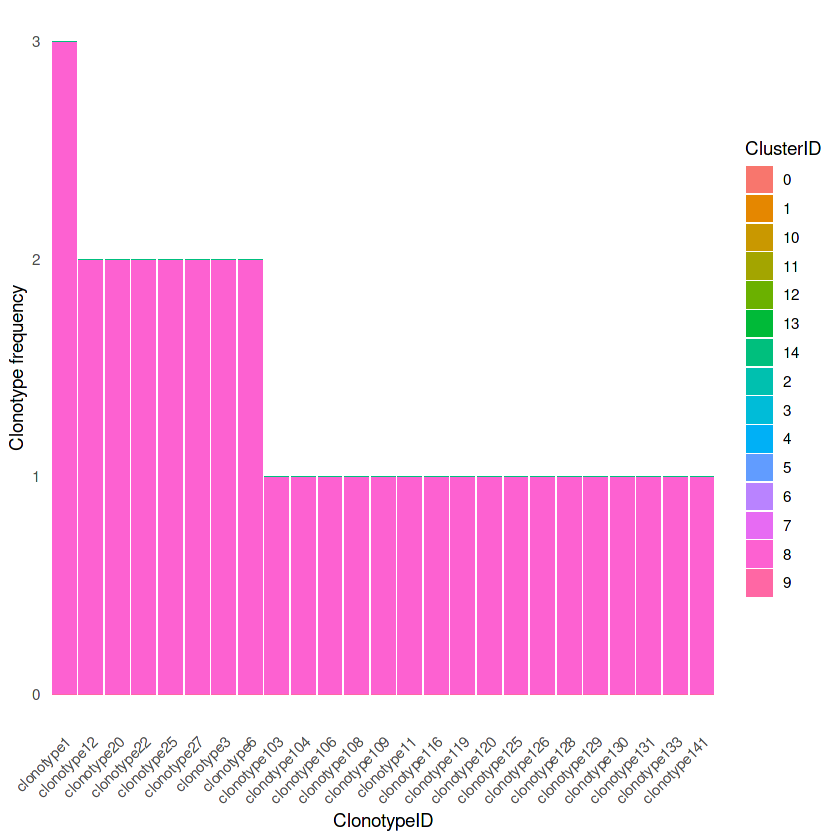

In [58]:
ggplot(ct2_df, aes(fill=ClusterID, y=Count, x=ClonotypeID)) + 
    geom_bar(position="stack", stat="identity")+scale_x_discrete(limits=top25_clonotype_names) +theme_minimal()+ 
theme(panel.grid.major = element_blank(), panel.grid.minor = element_blank(),axis.text.x = element_text(angle = 45, hjust = 1)) + ylab("Clonotype frequency")-> C2_PLOTbcell
C2_PLOTbcell


In [139]:
#ggsave("/media/igl2/828f6e4d-cda7-48c0-99c1-478e80aeecda/Shubham/clonotype_AS/2_PLOT.png", plot = C2_PLOTtcell, width = 10, height = 6, dpi = 300)


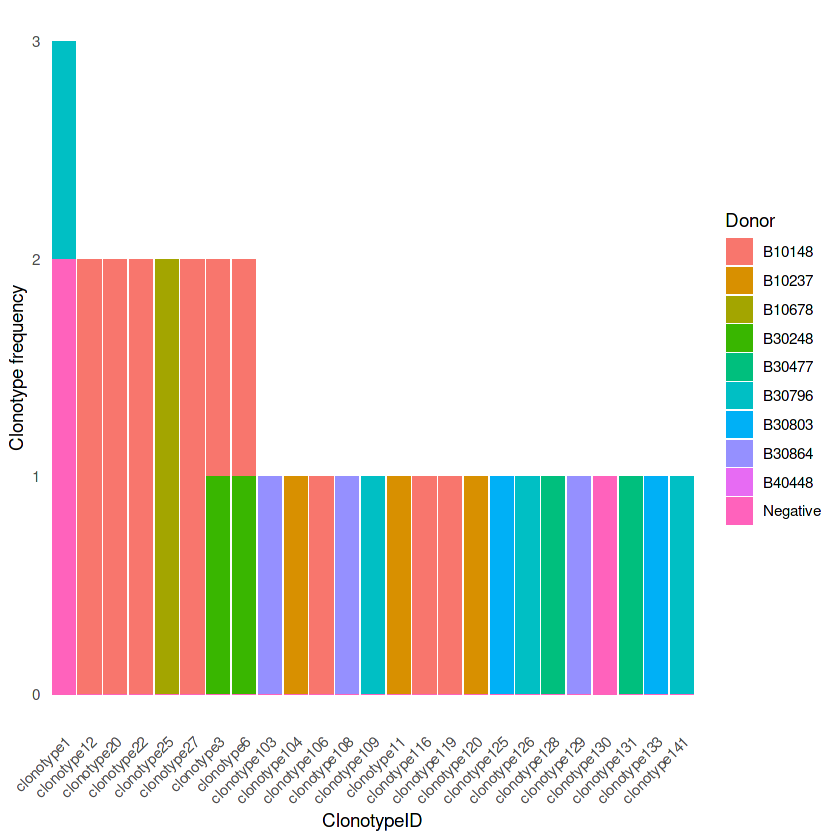

In [59]:
contig_PR <- ggplot(ct2_df.Donor, aes(fill=Donor, y=Count, x=ClonotypeID)) + 
    geom_bar(position="stack", stat="identity") + 
    scale_x_discrete(limits=top25_clonotype_names) + 
    theme_minimal() + 
    theme(
        panel.grid.major = element_blank(), 
        panel.grid.minor = element_blank(), 
        panel.background = element_rect(fill = "white", color = NA),  # White background
        plot.background = element_rect(fill = "white", color = NA),   # White plot background
        legend.background = element_rect(fill = "white", color = NA), # White legend background
        axis.text.x = element_text(angle = 45, hjust = 1)  # Tilt x-axis labels
    ) +  
    ylab("Clonotype frequency")

contig_PR


In [60]:
ggsave("/media/igl2/828f6e4d-cda7-48c0-99c1-478e80aeecda/Shubham/clonotype_DS2/donor_clonotype.png", plot = contig_PR, width = 10, height = 6, dpi = 300)
